# EcoSense - Anomaly Detection

**Pipeline:** Setup → Load → First look → Cleaning → EDA → Feature engineering → Model → Evaluation

## 1. Setup

In [1]:
import logging
from pathlib import Path

import numpy as np
import pandas as pd

# Constants
SEED = 42
DATA_PATH = Path("factory_data.csv")
CLEAN_PATH = Path("factory_clean.csv")
LOG_PATH = Path("ecosense.log")

TIME_COL = "timestamp"
METER_COLS = ["machines_kwh", "cooling_kwh", "compressed_air_kwh",
              "lighting_kwh", "other_kwh"]
OTHER_COLS = ["total_kwh", "water_m3", "fuel_liters", "temp_c", "production_level"]
TARGET_COLS = ["is_anomaly", "anomaly_type"]  # labels: never use as features
REQUIRED_COLS = [TIME_COL] + METER_COLS + OTHER_COLS + TARGET_COLS
NON_NEGATIVE_COLS = METER_COLS + ["total_kwh", "water_m3", "fuel_liters"]
SENSOR_COLS = NON_NEGATIVE_COLS + ["temp_c", "production_level"]

np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

# Logging to console and file
logger = logging.getLogger("ecosense")
logger.setLevel(logging.INFO)
if not logger.handlers:  # avoid duplicate handlers on re-run
    fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
    for h in (logging.StreamHandler(), logging.FileHandler(LOG_PATH, encoding="utf-8")):
        h.setFormatter(fmt)
        logger.addHandler(h)

logger.info("Setup done (seed=%s)", SEED)

23:22:47 | INFO    | Setup done (seed=42)


## 2. Load data

In [2]:
def load_data(path: Path, required_cols: list) -> pd.DataFrame:
    """Read the CSV and validate that required columns exist."""
    try:
        df = pd.read_csv(path, parse_dates=[TIME_COL])
    except FileNotFoundError:
        logger.error("File not found: %s", path)
        raise
    except (pd.errors.EmptyDataError, pd.errors.ParserError) as e:
        logger.error("Cannot read %s: %s", path, e)
        raise

    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        logger.error("Missing columns: %s", missing)
        raise ValueError(f"Missing columns: {missing}")

    # Empty anomaly_type means "normal" (pandas reads it as NaN)
    df["anomaly_type"] = df["anomaly_type"].fillna("normal")

    logger.info("Loaded %d rows, %d columns", *df.shape)
    return df


df_raw = load_data(DATA_PATH, REQUIRED_COLS)
df_raw.head()

23:22:47 | INFO    | Loaded 8760 rows, 13 columns


,timestamp,temp_c,production_level,machines_kwh,cooling_kwh,compressed_air_kwh,lighting_kwh,other_kwh,total_kwh,water_m3,fuel_liters,anomaly_type,is_anomaly
0,2025-01-01 00:00:00,11.2,0.0,20.63,7.74,36.66,4.28,19.91,89.22,0.319,0.50,normal,0
1,2025-01-01 01:00:00,8.8,0.0,17.58,7.50,35.74,5.27,20.46,86.55,0.389,0.74,normal,0
2,2025-01-01 02:00:00,10.4,0.0,19.61,7.71,36.03,3.83,20.87,88.05,0.531,0.00,normal,0
3,2025-01-01 03:00:00,10.5,0.0,20.03,9.56,36.02,4.65,19.52,89.78,0.281,0.00,normal,0
4,2025-01-01 04:00:00,7.2,0.0,19.39,5.56,34.62,4.41,21.64,85.62,0.428,0.22,normal,0


## 3. First look

In [3]:
df = df_raw.copy()  # keep df_raw untouched
logger.info("Shape: %s | Period: %s -> %s", df.shape, df[TIME_COL].min(), df[TIME_COL].max())
df.info()

23:22:47 | INFO    | Shape: (8760, 13) | Period: 2025-01-01 00:00:00 -> 2025-12-31 23:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   timestamp           8760 non-null   datetime64[ns]
 1   temp_c              8760 non-null   float64       
 2   production_level    8760 non-null   float64       
 3   machines_kwh        8760 non-null   float64       
 4   cooling_kwh         8760 non-null   float64       
 5   compressed_air_kwh  8760 non-null   float64       
 6   lighting_kwh        8760 non-null   float64       
 7   other_kwh           8760 non-null   float64       
 8   total_kwh           8760 non-null   float64       
 9   water_m3            8760 non-null   float64       
 10  fuel_liters         8760 non-null   float64       
 11  anomaly_type        8760 non-null   object        
 12  is_anomaly          8760 non-null   int64         
dtypes: datetime64[ns](1), float64(10), int64(1), obj

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,8760,2025-07-02 11:30:00,2025-01-01 00:00:00,2025-04-02 05:45:00,2025-07-02 11:30:00,2025-10-01 17:15:00,2025-12-31 23:00:00,NaN
temp_c,8760.0,21.992454,6.1,16.9,21.9,27.0,38.3,6.796835
production_level,8760.0,0.460805,0.0,0.0,0.6,0.847,1.0,0.411682
machines_kwh,8760.0,120.797584,4.49,19.2475,154.18,204.75,349.16,90.745913
cooling_kwh,8760.0,39.426677,0.57,15.41,29.195,57.7525,169.99,31.36813
compressed_air_kwh,8760.0,78.33857,26.62,38.73,91.97,110.55,155.9,35.686438
lighting_kwh,8760.0,16.851377,0.95,4.2,25.15,26.13,29.27,10.864667
other_kwh,8760.0,24.580411,13.04,20.39,25.16,28.4825,37.04,4.554427
total_kwh,8760.0,279.994619,66.16,100.675,342.635,426.855,591.26,161.300379
water_m3,8760.0,1.906326,0.069,0.427,2.408,3.12,5.395,1.339424


### Data quality report
One function, used before and after cleaning.

In [5]:
def quality_report(df: pd.DataFrame) -> pd.Series:
    """Count common data problems."""
    gaps = df[TIME_COL].sort_values().diff().dropna()
    report = pd.Series({
        "missing_values": df[SENSOR_COLS].isna().sum().sum(),
        "duplicate_timestamps": df[TIME_COL].duplicated().sum(),
        "negative_readings": (df[NON_NEGATIVE_COLS] < 0).sum().sum(),
        "time_gaps": (gaps != pd.Timedelta("1h")).sum(),
        "total_mismatch": (df[METER_COLS].sum(axis=1) - df["total_kwh"]).abs().gt(0.1).sum(),
    }).astype(int)
    for name, value in report.items():
        (logger.warning if value else logger.info)("%s: %d", name, value)
    return report


report_before = quality_report(df)
report_before

23:22:47 | INFO    | missing_values: 0
23:22:47 | INFO    | duplicate_timestamps: 0
23:22:47 | INFO    | negative_readings: 0
23:22:47 | INFO    | time_gaps: 0
23:22:47 | INFO    | total_mismatch: 0


missing_values          0
duplicate_timestamps    0
negative_readings       0
time_gaps               0
total_mismatch          0
dtype: int64

In [6]:
# Label distribution (labels are for evaluation only)
df["anomaly_type"].value_counts()

anomaly_type
normal                  7468
chiller_degradation      624
compressed_air_leak      336
water_leak               156
idle_machines_friday      72
lights_left_on            64
equipment_spike           40
Name: count, dtype: int64

## 4. Cleaning

In [7]:
def clean_data(df: pd.DataFrame, max_gap_hours: int = 3) -> pd.DataFrame:
    """Sort, drop duplicates, null impossible values, fill short gaps."""
    df = df.copy()
    n_start = len(df)

    # 1. Sort and drop duplicate timestamps
    df = df.sort_values(TIME_COL).drop_duplicates(subset=TIME_COL, keep="first")

    # 2. Negative readings are impossible -> mark as missing
    df[NON_NEGATIVE_COLS] = df[NON_NEGATIVE_COLS].mask(df[NON_NEGATIVE_COLS] < 0)

    # 3. Rebuild a complete hourly index (exposes time gaps as NaN rows)
    df = df.set_index(TIME_COL).asfreq("h")

    # 4. Fill short gaps only; long gaps stay missing and get dropped
    df[SENSOR_COLS] = df[SENSOR_COLS].interpolate(method="time", limit=max_gap_hours)
    df["is_anomaly"] = df["is_anomaly"].fillna(0).astype(int)
    df["anomaly_type"] = df["anomaly_type"].fillna("normal")
    df = df.dropna(subset=SENSOR_COLS)

    # 5. Recompute total from meters so it stays consistent
    df["total_kwh"] = df[METER_COLS].sum(axis=1).round(2)

    logger.info("Cleaning done: %d -> %d rows", n_start, len(df))
    return df.reset_index()


df_clean = clean_data(df)
report_after = quality_report(df_clean)

23:22:47 | INFO    | Cleaning done: 8760 -> 8760 rows
23:22:47 | INFO    | missing_values: 0
23:22:47 | INFO    | duplicate_timestamps: 0
23:22:47 | INFO    | negative_readings: 0
23:22:47 | INFO    | time_gaps: 0
23:22:47 | INFO    | total_mismatch: 0


### Before vs after

In [8]:
pd.DataFrame({"before": report_before, "after": report_after})

,before,after
missing_values,0,0
duplicate_timestamps,0,0
negative_readings,0,0
time_gaps,0,0
total_mismatch,0,0


In [9]:
df_clean.head()

,timestamp,temp_c,production_level,machines_kwh,cooling_kwh,compressed_air_kwh,lighting_kwh,other_kwh,total_kwh,water_m3,fuel_liters,anomaly_type,is_anomaly
0,2025-01-01 00:00:00,11.2,0.0,20.63,7.74,36.66,4.28,19.91,89.22,0.319,0.50,normal,0
1,2025-01-01 01:00:00,8.8,0.0,17.58,7.50,35.74,5.27,20.46,86.55,0.389,0.74,normal,0
2,2025-01-01 02:00:00,10.4,0.0,19.61,7.71,36.03,3.83,20.87,88.05,0.531,0.00,normal,0
3,2025-01-01 03:00:00,10.5,0.0,20.03,9.56,36.02,4.65,19.52,89.78,0.281,0.00,normal,0
4,2025-01-01 04:00:00,7.2,0.0,19.39,5.56,34.62,4.41,21.64,85.62,0.428,0.22,normal,0


In [10]:
df_clean.to_csv(CLEAN_PATH, index=False)
logger.info("Saved cleaned data to %s", CLEAN_PATH)

23:22:47 | INFO    | Saved cleaned data to factory_clean.csv


## 5. EDA
### 5.1 Consumption overview

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", rc={"figure.figsize": (12, 4)})
df_eda = df_clean.set_index(TIME_COL)  # time-indexed copy for EDA
normal = df_eda[df_eda["is_anomaly"] == 0]  # healthy hours only

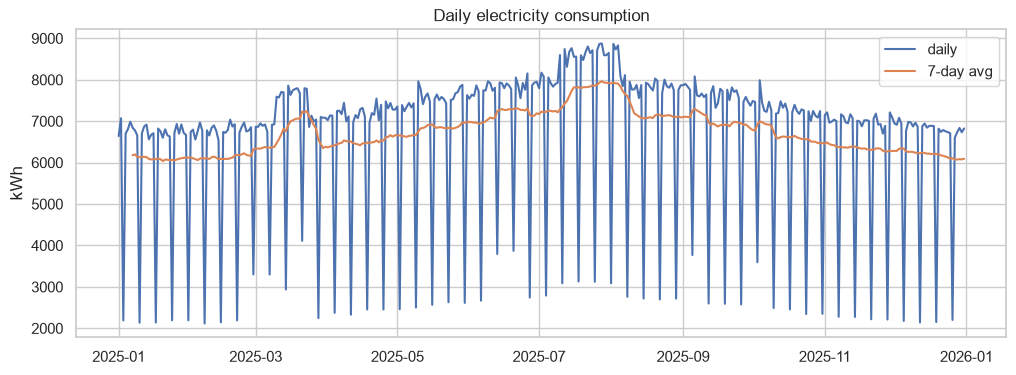

In [12]:
# Daily electricity consumption with 7-day average
daily = df_eda["total_kwh"].resample("D").sum().rename("daily").to_frame()
daily["7-day avg"] = daily["daily"].rolling(7).mean()
ax = sns.lineplot(data=daily, dashes=False)
ax.set(title="Daily electricity consumption", xlabel="", ylabel="kWh")
plt.show()

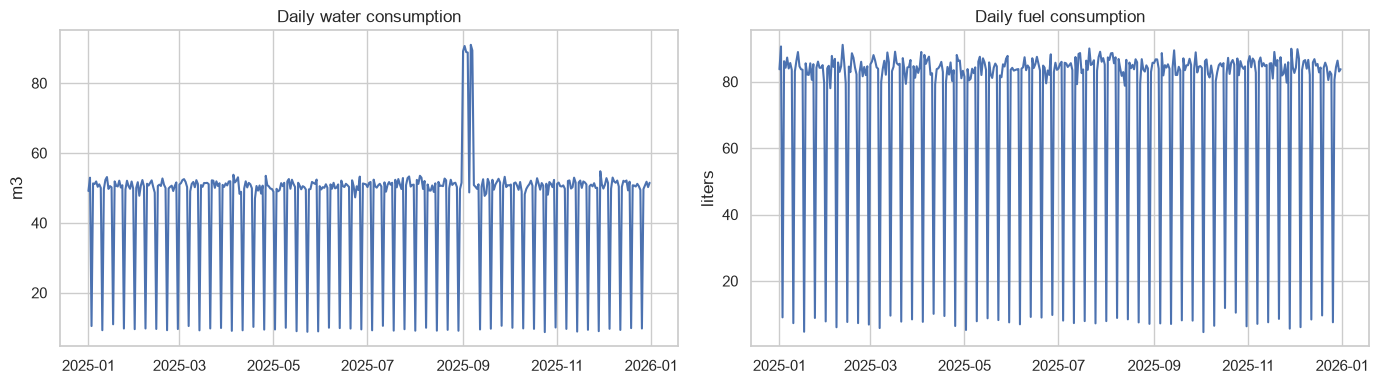

In [13]:
# Daily water and fuel consumption
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, unit in zip(axes, ["water_m3", "fuel_liters"], ["m3", "liters"]):
    daily_col = df_eda[col].resample("D").sum()
    sns.lineplot(x=daily_col.index, y=daily_col.values, ax=ax)
    ax.set(title=f"Daily {col.split('_')[0]} consumption", xlabel="", ylabel=unit)
plt.tight_layout()
plt.show()

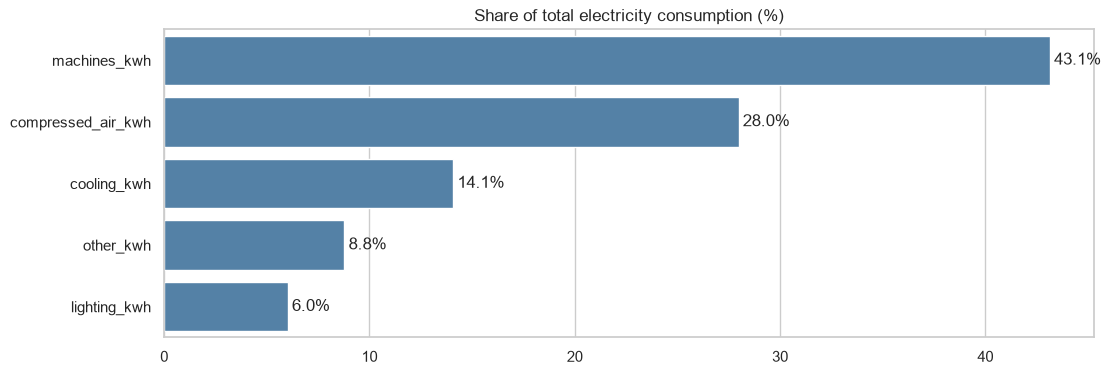

In [14]:
# Share of each electricity meter
share = (df_eda[METER_COLS].sum() / df_eda["total_kwh"].sum() * 100).sort_values(ascending=False)
ax = sns.barplot(x=share.values, y=share.index, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="Share of total electricity consumption (%)", xlabel="", ylabel="")
plt.show()

### 5.2 Daily pattern (healthy hours only)

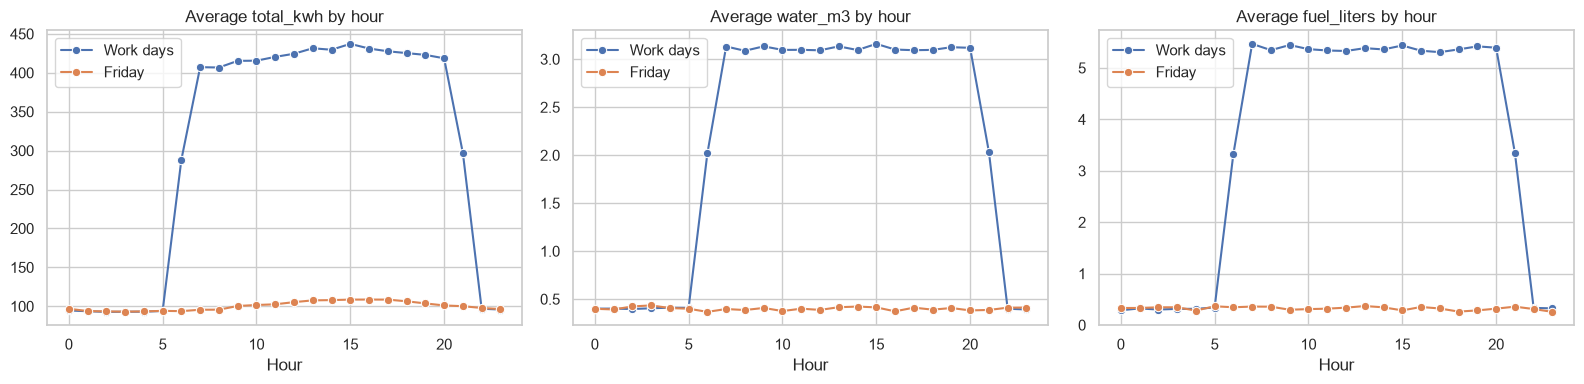

In [15]:
# Average load by hour: work days vs Friday
day_type = np.where(normal.index.dayofweek == 4, "Friday", "Work days")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["total_kwh", "water_m3", "fuel_liters"]):
    sns.lineplot(x=normal.index.hour, y=normal[col], hue=day_type,
                 marker="o", errorbar=None, ax=ax)
    ax.set(title=f"Average {col} by hour", xlabel="Hour", ylabel="")
plt.tight_layout()
plt.show()

### 5.3 Healthy vs anomalous hours
For each anomaly type: average value by hour of day for its affected meter, against healthy hours from the same months and day types.

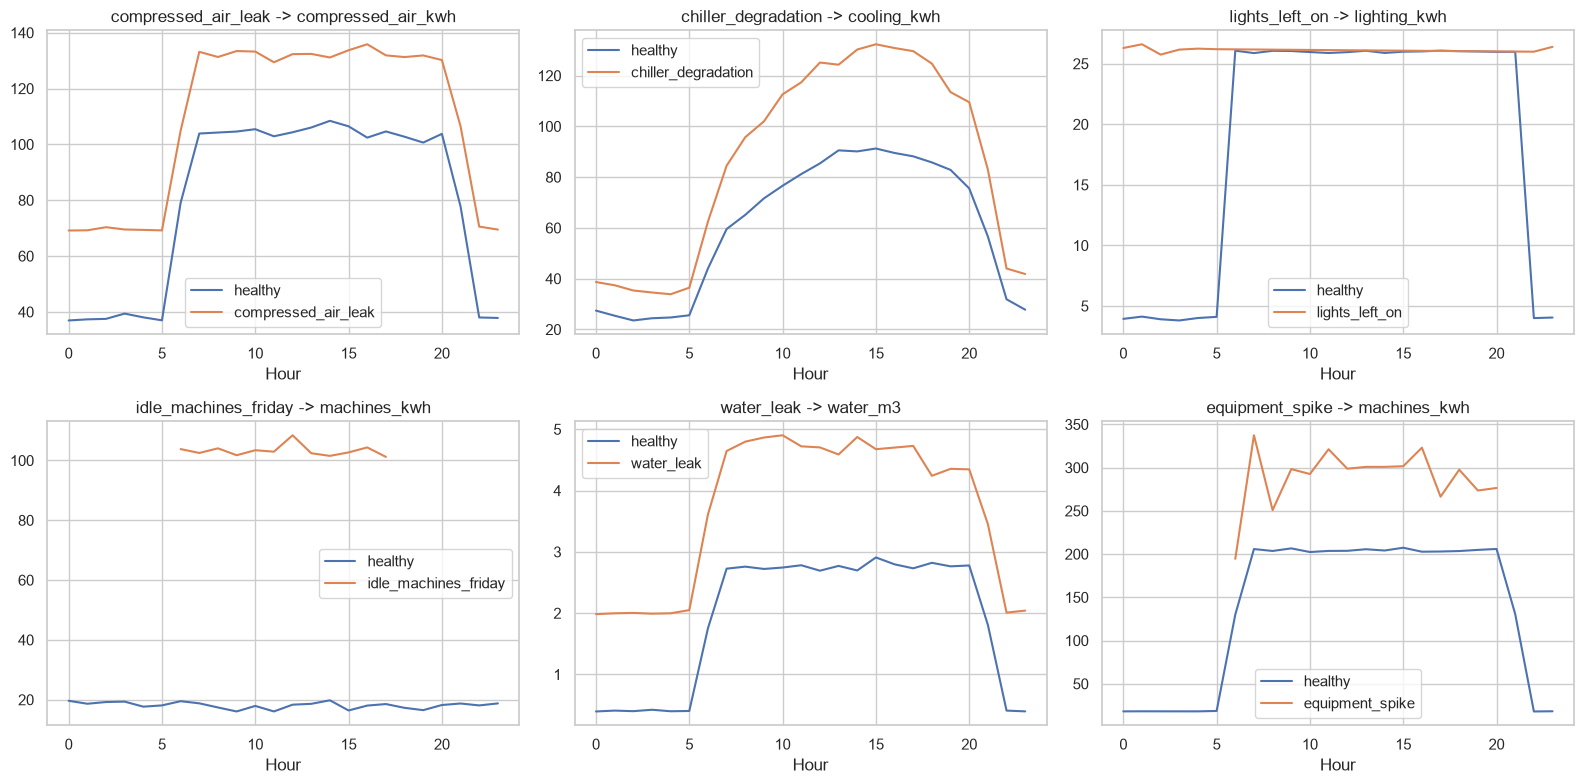

In [16]:
AFFECTED_METER = {
    "compressed_air_leak": "compressed_air_kwh",
    "chiller_degradation": "cooling_kwh",
    "lights_left_on": "lighting_kwh",
    "idle_machines_friday": "machines_kwh",
    "water_leak": "water_m3",
    "equipment_spike": "machines_kwh",
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (atype, meter) in zip(axes.flat, AFFECTED_METER.items()):
    anom = df_eda[df_eda["anomaly_type"] == atype]
    # reference: healthy hours, same months, same day types
    ref = normal[normal.index.month.isin(anom.index.month.unique())
                 & normal.index.dayofweek.isin(anom.index.dayofweek.unique())]
    sns.lineplot(x=ref.index.hour, y=ref[meter], errorbar=None, label="healthy", ax=ax)
    sns.lineplot(x=anom.index.hour, y=anom[meter], errorbar=None, label=atype, ax=ax)
    ax.set(title=f"{atype} -> {meter}", xlabel="Hour", ylabel="")
plt.tight_layout()
plt.show()

In [17]:
# How much does each anomaly type inflate its meter (mean vs healthy reference)?
rows = []
for atype, meter in AFFECTED_METER.items():
    anom = df_eda[df_eda["anomaly_type"] == atype]
    ref = normal[normal.index.month.isin(anom.index.month.unique())
                 & normal.index.dayofweek.isin(anom.index.dayofweek.unique())
                 & normal.index.hour.isin(anom.index.hour.unique())]
    rows.append({"anomaly": atype, "meter": meter, "hours": len(anom),
                 "increase_%": (anom[meter].mean() / ref[meter].mean() - 1) * 100})
pd.DataFrame(rows).round(1).sort_values("increase_%", ascending=False)

,anomaly,meter,hours,increase_%
2,lights_left_on,lighting_kwh,64,556.3
3,idle_machines_friday,machines_kwh,72,475.2
4,water_leak,water_m3,156,90.6
5,equipment_spike,machines_kwh,40,48.1
1,chiller_degradation,cooling_kwh,624,43.3
0,compressed_air_leak,compressed_air_kwh,336,38.3


### 5.4 Relationships

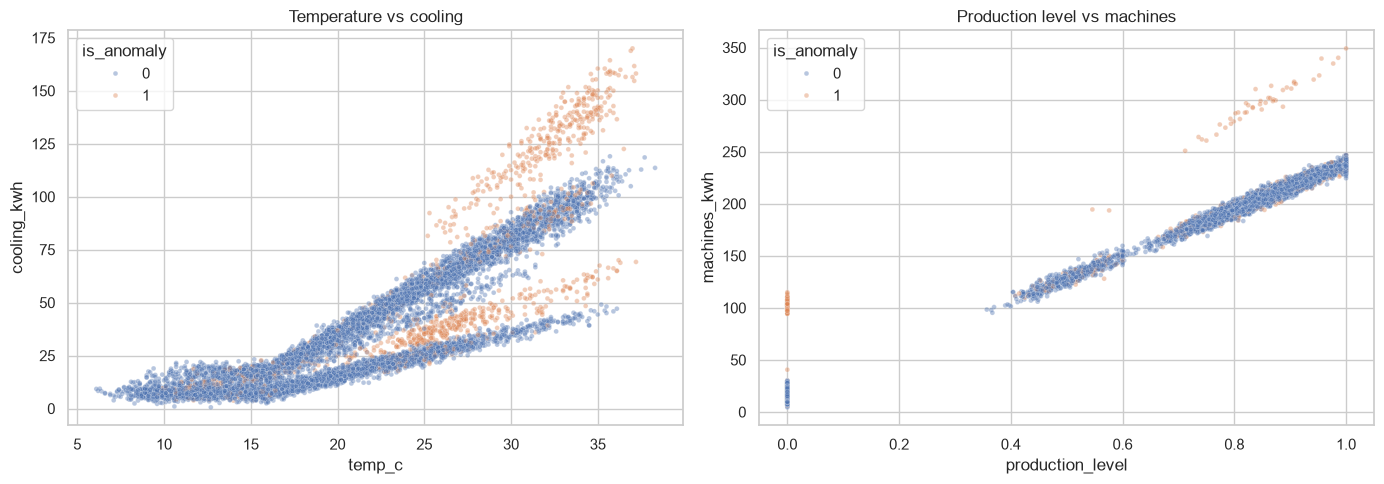

In [18]:
# Temperature vs cooling, production vs machines
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df_eda, x="temp_c", y="cooling_kwh", hue="is_anomaly",
                alpha=0.4, s=12, ax=axes[0])
sns.scatterplot(data=df_eda, x="production_level", y="machines_kwh", hue="is_anomaly",
                alpha=0.4, s=12, ax=axes[1])
axes[0].set(title="Temperature vs cooling")
axes[1].set(title="Production level vs machines")
plt.tight_layout()
plt.show()

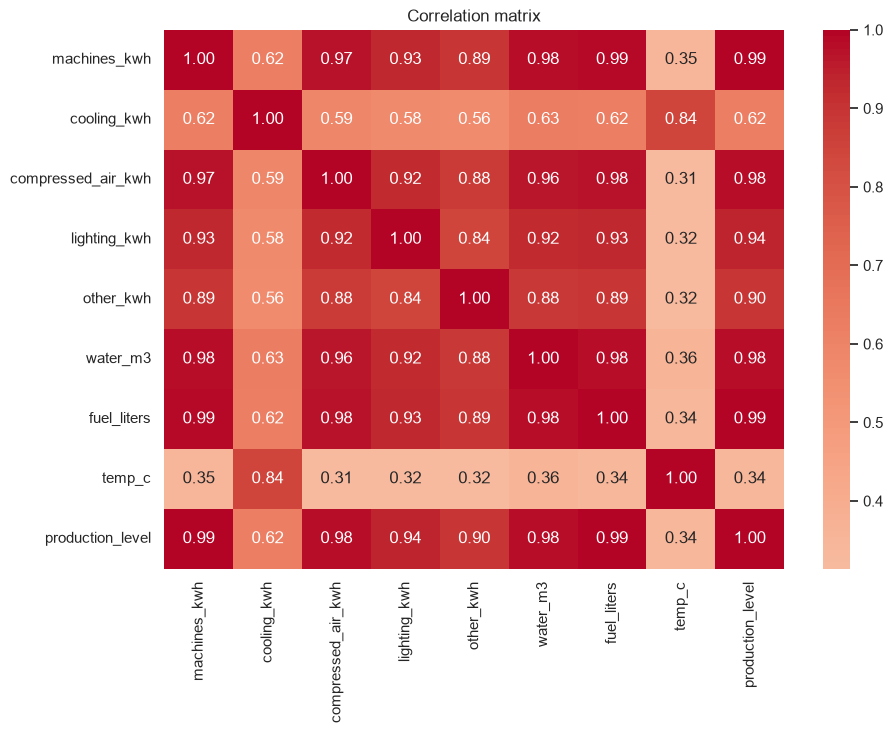

In [19]:
# Correlation matrix (all hours)
corr_cols = METER_COLS + ["water_m3", "fuel_liters", "temp_c", "production_level"]
plt.figure(figsize=(10, 7))
sns.heatmap(df_eda[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

### 5.5 Monthly consumption

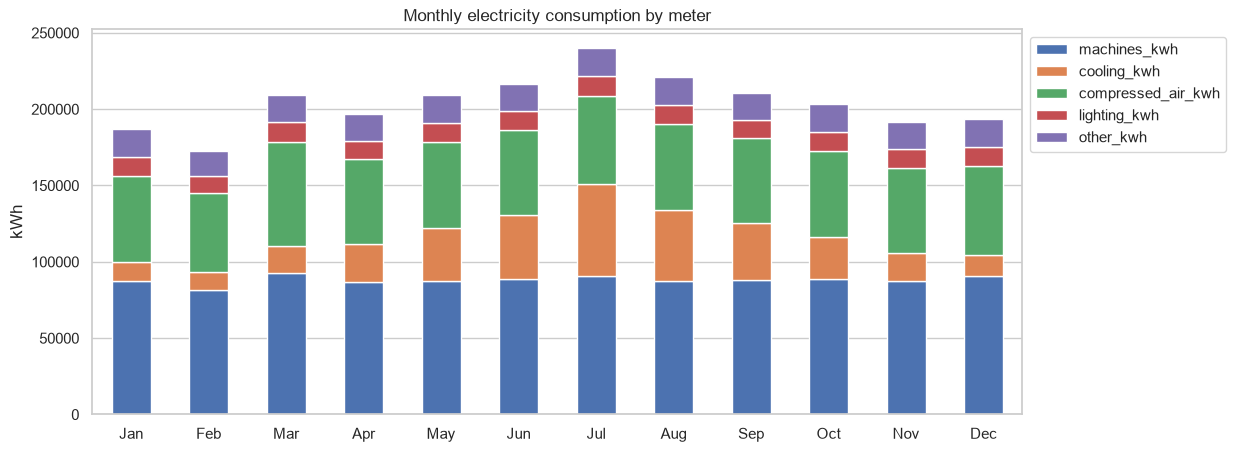

In [20]:
# Monthly electricity by meter (stacked)
monthly = df_eda[METER_COLS + ["water_m3", "fuel_liters"]].resample("MS").sum()
monthly.index = monthly.index.strftime("%b")
ax = monthly[METER_COLS].plot.bar(stacked=True, figsize=(12, 5), rot=0,
                                  color=sns.color_palette("deep", len(METER_COLS)))
ax.set(title="Monthly electricity consumption by meter", xlabel="", ylabel="kWh")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

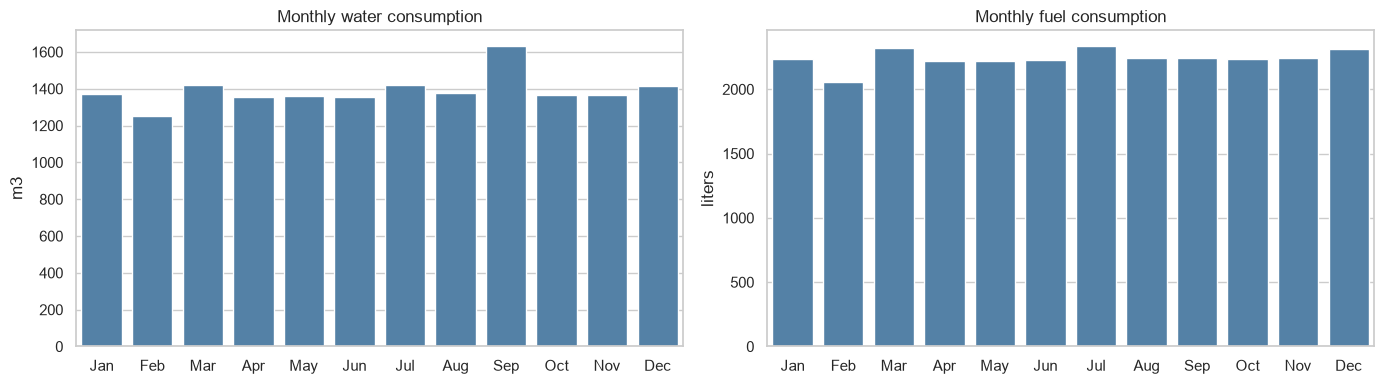

In [21]:
# Monthly water and fuel
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, unit in zip(axes, ["water_m3", "fuel_liters"], ["m3", "liters"]):
    sns.barplot(x=monthly.index, y=monthly[col], color="steelblue", ax=ax)
    ax.set(title=f"Monthly {col.split('_')[0]} consumption", xlabel="", ylabel=unit)
plt.tight_layout()
plt.show()

## 6. Feature engineering
Each feature group is a function, so the same code can be reused in the API.

### 6.1 Evaluation helper and baseline

In [22]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, precision_recall_curve

y = df_clean["is_anomaly"].values
results = {}  # experiment name -> metrics


def evaluate(name: str, score: np.ndarray) -> pd.DataFrame:
    """Store AP and best-threshold precision/recall/F1 for an anomaly score."""
    p, r, _ = precision_recall_curve(y, score)
    f1 = 2 * p * r / (p + r + 1e-9)
    best = f1.argmax()
    results[name] = {"AP": average_precision_score(y, score), "F1": f1[best],
                     "precision": p[best], "recall": r[best]}
    logger.info("%s | AP=%.3f F1=%.3f", name, results[name]["AP"], results[name]["F1"])
    return pd.DataFrame(results).T.round(3)


def isolation_score(X: pd.DataFrame) -> np.ndarray:
    """Unsupervised anomaly score (higher = more anomalous)."""
    model = IsolationForest(n_estimators=300, random_state=SEED).fit(X)
    return -model.score_samples(X)

In [23]:
def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """Hour (cyclic) and day-of-week features."""
    out = df.copy()
    out["hour"] = out[TIME_COL].dt.hour
    out["dow"] = out[TIME_COL].dt.dayofweek
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    return out


df_feat = add_time_features(df_clean)

BASE_FEATURES = METER_COLS + ["water_m3", "fuel_liters", "temp_c", "hour_sin", "hour_cos", "dow"]
evaluate("A_baseline", isolation_score(df_feat[BASE_FEATURES]))

23:23:02 | INFO    | A_baseline | AP=0.515 F1=0.540


,AP,F1,precision,recall
A_baseline,0.515,0.54,0.449,0.679


### 6.2 Deviation from typical load
Typical value = median per (day-of-week, hour). The table is fitted once and reused on new data.

In [24]:
DEV_COLS = METER_COLS + ["water_m3", "fuel_liters"]
DEV_FEATURES = [f"{c}_dev" for c in DEV_COLS]


def fit_typical_profile(df: pd.DataFrame) -> pd.DataFrame:
    """Median of each column per (dow, hour): 168 rows."""
    return df.groupby(["dow", "hour"])[DEV_COLS].median()


def add_deviation_features(df: pd.DataFrame, profile: pd.DataFrame) -> pd.DataFrame:
    """Actual value minus the typical value for the same (dow, hour)."""
    typical = df[["dow", "hour"]].join(profile, on=["dow", "hour"])[DEV_COLS]
    dev = df[DEV_COLS] - typical
    dev.columns = DEV_FEATURES
    return pd.concat([df, dev], axis=1)


typical_profile = fit_typical_profile(df_feat)
df_feat = add_deviation_features(df_feat, typical_profile)
typical_profile.head()

machines_kwh  cooling_kwh  compressed_air_kwh  lighting_kwh  \
dow hour                                                                
0   0           17.655       12.650              38.700         3.835   
    1           18.715       12.065              37.975         3.925   
    2           17.835       10.075              38.015         3.770   
    3           18.605       10.030              37.885         3.995   
    4           18.505       10.805              37.810         4.070   

          other_kwh  water_m3  fuel_liters  
dow hour                                    
0   0        20.680    0.3985        0.245  
    1        19.310    0.4075        0.365  
    2        20.145    0.3830        0.275  
    3        20.035    0.4325        0.240  
    4        19.595    0.4080        0.245

In [25]:
# Example: lighting at 2 AM is typically ~4 kWh; a "lights left on" night shows a large deviation
night = df_feat[(df_feat["hour"] == 2)]
night.groupby("anomaly_type")["lighting_kwh_dev"].mean().round(1)

anomaly_type
chiller_degradation     4.3
compressed_air_leak     1.5
lights_left_on         21.7
normal                 -0.0
water_leak              0.6
Name: lighting_kwh_dev, dtype: float64

In [26]:
B_FEATURES = BASE_FEATURES + DEV_FEATURES
evaluate("B_deviation", isolation_score(df_feat[B_FEATURES]))

23:23:03 | INFO    | B_deviation | AP=0.633 F1=0.631


,AP,F1,precision,recall
A_baseline,0.515,0.540,0.449,0.679
B_deviation,0.633,0.631,0.574,0.701


### 6.3 Meter shares and rolling deviation
- **Share:** each meter as a fraction of total kWh.
- **Rolling deviation:** value minus the mean of the last 24 hours (backward-looking only). Requires data sorted by time.

In [27]:
SHARE_FEATURES = [f"{c}_share" for c in METER_COLS]
ROLL_WINDOW = 24
ROLL_FEATURES = [f"{c}_roll{ROLL_WINDOW}_dev" for c in METER_COLS]


def add_share_features(df: pd.DataFrame) -> pd.DataFrame:
    """Each electricity meter as a fraction of total kWh."""
    out = df.copy()
    for c in METER_COLS:
        out[f"{c}_share"] = out[c] / out["total_kwh"]
    return out


def add_rolling_features(df: pd.DataFrame, window: int = ROLL_WINDOW) -> pd.DataFrame:
    """Value minus the mean of the last `window` hours (df must be sorted by time)."""
    out = df.copy()
    for c in METER_COLS:
        out[f"{c}_roll{window}_dev"] = out[c] - out[c].rolling(window, min_periods=1).mean()
    return out


df_feat = add_rolling_features(add_share_features(df_feat))
df_feat[SHARE_FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
machines_kwh_share,8760.0,0.354,0.149,0.056,0.195,0.433,0.483,0.632
cooling_kwh_share,8760.0,0.146,0.078,0.007,0.083,0.134,0.197,0.517
compressed_air_kwh_share,8760.0,0.318,0.080,0.157,0.256,0.284,0.380,0.660
lighting_kwh_share,8760.0,0.056,0.023,0.011,0.043,0.056,0.064,0.283
other_kwh_share,8760.0,0.126,0.070,0.044,0.066,0.079,0.196,0.316


In [28]:
C_FEATURES = B_FEATURES + SHARE_FEATURES + ROLL_FEATURES
evaluate("C_shares_rolling", isolation_score(df_feat[C_FEATURES]))

23:23:04 | INFO    | C_shares_rolling | AP=0.711 F1=0.634


,AP,F1,precision,recall
A_baseline,0.515,0.540,0.449,0.679
B_deviation,0.633,0.631,0.574,0.701
C_shares_rolling,0.711,0.634,0.595,0.679


### 6.4 Residuals from an expected-consumption model
For each meter, a small model predicts the expected value from production, temperature and time. Residual = actual - expected. Models are fitted once and reused (saved for the API).

In [29]:
from sklearn.ensemble import HistGradientBoostingRegressor

RES_INPUTS = ["hour", "dow", "temp_c", "production_level"]
RES_FEATURES = [f"{c}_res" for c in DEV_COLS]


def fit_baseline_models(df: pd.DataFrame) -> dict:
    """One small expected-consumption model per column (small = generalizes to unseen data)."""
    return {c: HistGradientBoostingRegressor(max_iter=50, min_samples_leaf=100, max_depth=4,
                                             random_state=SEED)
                .fit(df[RES_INPUTS], df[c]) for c in DEV_COLS}


def add_residual_features(df: pd.DataFrame, models: dict) -> pd.DataFrame:
    """Actual minus expected consumption for each column."""
    out = df.copy()
    for c, model in models.items():
        out[f"{c}_res"] = out[c] - model.predict(out[RES_INPUTS])
    return out


baseline_models = fit_baseline_models(df_feat)
df_feat = add_residual_features(df_feat, baseline_models)
df_feat[RES_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
machines_kwh_res,8760.0,-0.0,10.78,-26.18,-3.82,-0.73,2.14,112.05
cooling_kwh_res,8760.0,-0.0,6.19,-28.46,-2.51,-0.54,1.27,36.70
compressed_air_kwh_res,8760.0,0.0,6.53,-13.97,-3.18,-0.91,1.42,40.53
lighting_kwh_res,8760.0,-0.0,2.44,-6.92,-0.76,-0.16,0.44,22.35
other_kwh_res,8760.0,0.0,1.98,-7.07,-1.34,-0.01,1.31,8.31
water_m3_res,8760.0,0.0,0.24,-0.47,-0.10,-0.03,0.05,1.83
fuel_liters_res,8760.0,-0.0,0.28,-1.13,-0.21,-0.01,0.19,1.20


In [30]:
# Residuals should be ~0 for healthy hours and positive for the matching anomaly
(df_feat.groupby("anomaly_type")[["compressed_air_kwh_res", "cooling_kwh_res",
                                  "lighting_kwh_res", "water_m3_res"]].mean().round(1))

,compressed_air_kwh_res,cooling_kwh_res,lighting_kwh_res,water_m3_res
anomaly_type,,,,
chiller_degradation,-0.1,16.5,0.8,-0.1
compressed_air_leak,28.1,0.1,0.3,-0.0
equipment_spike,-1.1,-0.6,0.0,-0.0
idle_machines_friday,-1.9,5.7,-0.1,0.2
lights_left_on,-1.0,-1.1,19.7,-0.1
normal,-1.2,-1.3,-0.2,-0.0
water_leak,0.4,-3.5,-0.5,1.5


In [31]:
D_FEATURES = RES_FEATURES + ["hour_sin", "hour_cos"]
evaluate("D_residuals", isolation_score(df_feat[D_FEATURES]))

23:23:08 | INFO    | D_residuals | AP=0.851 F1=0.777


,AP,F1,precision,recall
A_baseline,0.515,0.540,0.449,0.679
B_deviation,0.633,0.631,0.574,0.701
C_shares_rolling,0.711,0.634,0.595,0.679
D_residuals,0.851,0.777,0.867,0.704


### 6.5 Rolling residuals (6h and 48h)
Sustained problems (leaks, degradation) keep the residual positive for many hours, while noise averages out. Windows are backward-looking only, so the same code works on live data.

In [32]:
ROLL_WINDOWS = (6, 48)


def add_residual_rolling(df: pd.DataFrame, windows=ROLL_WINDOWS) -> pd.DataFrame:
    """Trailing mean of each residual over several windows."""
    out = df.copy()
    for c in RES_FEATURES:
        for w in windows:
            out[f"{c}_roll{w}"] = out[c].rolling(w, min_periods=1).mean()
    return out


df_feat = add_residual_rolling(df_feat)
RES_ROLL_FEATURES = [f"{c}_roll{w}" for c in RES_FEATURES for w in ROLL_WINDOWS]
df_feat[RES_ROLL_FEATURES].describe().T.round(2).head(8)

,count,mean,std,min,25%,50%,75%,max
machines_kwh_res_roll6,8760.0,0.0,8.08,-17.11,-1.94,-0.64,0.62,76.77
machines_kwh_res_roll48,8760.0,-0.0,4.10,-4.93,-1.56,-0.65,0.06,28.89
cooling_kwh_res_roll6,8760.0,-0.0,5.55,-17.44,-1.65,-0.49,0.39,31.06
cooling_kwh_res_roll48,8760.0,-0.0,4.88,-7.24,-1.42,-0.34,0.04,18.84
compressed_air_kwh_res_roll6,8760.0,-0.0,5.83,-7.72,-2.21,-0.91,0.23,32.08
compressed_air_kwh_res_roll48,8760.0,-0.0,5.56,-4.61,-2.00,-0.82,-0.07,28.79
lighting_kwh_res_roll6,8760.0,0.0,1.83,-5.17,-0.46,-0.13,0.15,21.33
lighting_kwh_res_roll48,8760.0,-0.0,0.93,-1.30,-0.32,-0.17,-0.05,6.88


In [33]:
# Sustained anomalies should now stand out more clearly
(df_feat.groupby("anomaly_type")[["compressed_air_kwh_res_roll48", "cooling_kwh_res_roll48",
                                  "water_m3_res_roll48"]].mean().round(1))

,compressed_air_kwh_res_roll48,cooling_kwh_res_roll48,water_m3_res_roll48
anomaly_type,,,
chiller_degradation,-0.2,15.4,-0.1
compressed_air_leak,25.8,0.1,-0.0
equipment_spike,-1.0,-0.2,-0.0
idle_machines_friday,-1.1,-0.9,0.2
lights_left_on,-0.6,-2.4,-0.0
normal,-1.1,-1.2,-0.0
water_leak,0.2,-3.2,1.3


In [34]:
E_FEATURES = RES_FEATURES + RES_ROLL_FEATURES + ["hour_sin", "hour_cos"]
evaluate("E_res_rolling", isolation_score(df_feat[E_FEATURES]))

23:23:09 | INFO    | E_res_rolling | AP=0.944 F1=0.865


,AP,F1,precision,recall
A_baseline,0.515,0.540,0.449,0.679
B_deviation,0.633,0.631,0.574,0.701
C_shares_rolling,0.711,0.634,0.595,0.679
D_residuals,0.851,0.777,0.867,0.704
E_res_rolling,0.944,0.865,0.883,0.849


## 7. Detection
Turn the anomaly score into decisions: (1) flag unhealthy hours with a fixed threshold, (2) find which meter is responsible, (3) merge consecutive flagged hours into events.

### 7.1 Detector and threshold
In real use there are no labels, so the threshold comes from the training scores: we assume about 15% of hours are abnormal and flag the top 15%. This is a sensitivity knob (higher rate = more recall, lower precision).

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

EXPECTED_ANOMALY_RATE = 0.15
DETECT_FEATURES = E_FEATURES


def fit_detector(df: pd.DataFrame, rate: float = EXPECTED_ANOMALY_RATE):
    """Fit IsolationForest; threshold = score quantile for the expected anomaly rate."""
    model = IsolationForest(n_estimators=300, random_state=SEED).fit(df[DETECT_FEATURES])
    threshold = np.quantile(-model.score_samples(df[DETECT_FEATURES]), 1 - rate)
    return model, threshold


def add_detection(df: pd.DataFrame, model, threshold: float) -> pd.DataFrame:
    """Add anomaly score and a flag for each hour."""
    out = df.copy()
    out["score"] = -model.score_samples(out[DETECT_FEATURES])
    out["is_flagged"] = out["score"] > threshold
    return out


detector, threshold = fit_detector(df_feat)
df_feat = add_detection(df_feat, detector, threshold)

y_true, y_pred = df_feat["is_anomaly"], df_feat["is_flagged"]
pd.Series({"threshold": threshold,
           "precision": precision_score(y_true, y_pred),
           "recall": recall_score(y_true, y_pred),
           "F1": f1_score(y_true, y_pred),
           "flagged_hours": int(y_pred.sum())}).round(3)

threshold           0.444
precision           0.849
recall              0.864
F1                  0.856
flagged_hours    1314.000
dtype: float64

### 7.2 Which meter is responsible?
For each flagged hour, take the meter with the largest 6h residual. Residuals are divided by each meter's typical spread first, so a big meter does not win just because its numbers are bigger.

In [36]:
RES6_COLS = [f"{c}_res_roll6" for c in DEV_COLS]


def fit_residual_scale(df: pd.DataFrame) -> pd.Series:
    """Typical spread (std) of each 6h residual, used to compare meters fairly."""
    return df[RES6_COLS].std()


def add_affected_meter(df: pd.DataFrame, scale: pd.Series) -> pd.DataFrame:
    """Meter with the largest scaled positive residual in each hour."""
    out = df.copy()
    scaled = out[RES6_COLS] / scale
    out["affected"] = scaled.idxmax(axis=1).str.replace("_res_roll6", "", regex=False)
    return out


res_scale = fit_residual_scale(df_feat)
df_feat = add_affected_meter(df_feat, res_scale)

flagged = df_feat[df_feat["is_flagged"]]
pd.crosstab(flagged["anomaly_type"], flagged["affected"])

affected,compressed_air_kwh,cooling_kwh,fuel_liters,lighting_kwh,machines_kwh,other_kwh,water_m3
anomaly_type,,,,,,,
chiller_degradation,0,385,10,62,8,3,0
compressed_air_leak,314,0,0,7,12,0,0
equipment_spike,0,0,0,0,28,0,0
idle_machines_friday,0,0,0,0,66,0,4
lights_left_on,0,0,3,57,0,1,0
normal,13,5,46,46,47,33,8
water_leak,0,0,0,0,1,1,154


### 7.3 Group hours into events
Consecutive flagged hours (gaps up to 3h allowed) become one event with a start, end and affected meter (majority vote). Events shorter than 3 hours are dropped as noise (trade-off: a few real 1-2h spikes are lost, but many false alarms disappear).

In [37]:
def group_events(df: pd.DataFrame, max_gap_hours: int = 3, min_hours: int = 3) -> pd.DataFrame:
    """Merge nearby flagged hours into events."""
    cols = ["start", "end", "hours", "meter", "mean_score"]
    flagged = df[df["is_flagged"]]
    if flagged.empty:
        return pd.DataFrame(columns=cols)
    new_event = flagged[TIME_COL].diff() > pd.Timedelta(hours=max_gap_hours)
    events = flagged.groupby(new_event.cumsum()).agg(
        start=(TIME_COL, "min"), end=(TIME_COL, "max"), hours=(TIME_COL, "size"),
        meter=("affected", lambda s: s.mode().iat[0]), mean_score=("score", "mean"))
    return events[events["hours"] >= min_hours].reset_index(drop=True)


events = group_events(df_feat)
logger.info("Detected %d events", len(events))
events.head(10).round(2)

23:23:10 | INFO    | Detected 47 events


,start,end,hours,meter,mean_score
0,2025-02-20 01:00:00,2025-02-20 07:00:00,7,lighting_kwh,0.48
1,2025-02-20 22:00:00,2025-02-21 00:00:00,3,lighting_kwh,0.47
2,2025-02-28 06:00:00,2025-03-01 01:00:00,18,machines_kwh,0.50
3,2025-03-07 07:00:00,2025-03-07 23:00:00,16,machines_kwh,0.49
4,2025-03-08 08:00:00,2025-03-08 16:00:00,9,machines_kwh,0.48
5,2025-03-09 04:00:00,2025-03-09 11:00:00,7,other_kwh,0.46
6,2025-03-10 03:00:00,2025-03-24 00:00:00,334,compressed_air_kwh,0.52
7,2025-03-24 18:00:00,2025-03-24 20:00:00,3,other_kwh,0.46
8,2025-05-10 12:00:00,2025-05-10 17:00:00,6,machines_kwh,0.47
9,2025-05-11 00:00:00,2025-05-11 07:00:00,8,lighting_kwh,0.47


In [38]:
# Sanity check against labels (for evaluation only, never used for detection)
def event_hit(row) -> bool:
    """An event is correct if most of its span is truly abnormal."""
    span = df_feat[(df_feat[TIME_COL] >= row["start"]) & (df_feat[TIME_COL] <= row["end"])]
    return span["is_anomaly"].mean() > 0.5


events["correct"] = events.apply(event_hit, axis=1)
print(f"Event precision: {events['correct'].mean():.2f}  ({len(events)} events)")

# True episodes per anomaly type and how many we caught
true_hours = df_feat[df_feat["is_anomaly"] == 1]
episode = ((true_hours[TIME_COL].diff() > pd.Timedelta(hours=3)) |
           (true_hours["anomaly_type"] != true_hours["anomaly_type"].shift())).cumsum()
episodes = true_hours.groupby(episode).agg(type=("anomaly_type", "first"),
                                           caught=("is_flagged", "any"))
episodes.groupby("type")["caught"].agg(episodes="size", caught="sum")

Event precision: 0.66  (47 events)


,episodes,caught
type,,
chiller_degradation,1,1
compressed_air_leak,1,1
equipment_spike,21,14
idle_machines_friday,6,6
lights_left_on,15,15
water_leak,2,2


## 8. Waste estimation
For each event: waste = sum of the positive residuals (actual minus expected) of the responsible meter over the event, converted to EGP and CO2 with the reference values in `ref_params.py` (approximate, must be verified before the demo).

**Step 8.1 - cleaner baseline.** The first baseline models were trained on all hours, including abnormal ones, so they partly learned the waste and under-estimate it. Second pass: refit the same models on the hours that were *not* flagged (no labels needed) and recompute residuals.

In [39]:
# Second pass: expected-consumption models trained on unflagged (healthy) hours only
baseline_models_clean = fit_baseline_models(df_feat[~df_feat["is_flagged"]])
df_waste = add_residual_features(df_feat, baseline_models_clean)

# Healthy hours should now average ~0 residual
df_waste.loc[~df_waste["is_flagged"], RES_FEATURES].mean().round(2)

machines_kwh_res          0.0
cooling_kwh_res           0.0
compressed_air_kwh_res    0.0
lighting_kwh_res          0.0
other_kwh_res            -0.0
water_m3_res              0.0
fuel_liters_res           0.0
dtype: float64

### 8.2 Convert waste to EGP and CO2

In [40]:
from ref_params import REF

# Price and emission factor per unit of each meter (kWh, m3 or liter)
UNIT_PRICE = {m: REF["tariff_egp_per_kwh"] for m in METER_COLS}
UNIT_PRICE.update(water_m3=REF["water_egp_per_m3"], fuel_liters=REF["diesel_egp_per_liter"])
UNIT_CO2 = {m: REF["grid_emission_kg_per_kwh"] for m in METER_COLS}
UNIT_CO2.update(water_m3=0.0, fuel_liters=REF["diesel_emission_kg_per_liter"])
UNIT_NAME = {m: "kWh" for m in METER_COLS}
UNIT_NAME.update(water_m3="m3", fuel_liters="liter")


def estimate_waste(df: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Add waste quantity, cost (EGP) and CO2 (kg) to each event. df must hold the clean residuals."""
    out = events.copy()
    qty = []
    for _, ev in out.iterrows():
        span = df[(df[TIME_COL] >= ev["start"]) & (df[TIME_COL] <= ev["end"])]
        qty.append(span[f"{ev['meter']}_res"].clip(lower=0).sum())  # only excess, never negative
    out["unit"] = out["meter"].map(UNIT_NAME)
    out["waste_qty"] = qty
    out["waste_egp"] = out["waste_qty"] * out["meter"].map(UNIT_PRICE)
    out["waste_co2_kg"] = out["waste_qty"] * out["meter"].map(UNIT_CO2)
    return out


events = estimate_waste(df_waste, group_events(df_feat))
events["correct"] = events.apply(event_hit, axis=1)  # label check, evaluation only

summary = events.groupby("meter").agg(events=("start", "size"), hours=("hours", "sum"),
                                      waste_qty=("waste_qty", "sum"), waste_egp=("waste_egp", "sum"),
                                      co2_kg=("waste_co2_kg", "sum")).round(0)
logger.info("Total waste: %.0f EGP, %.0f kg CO2", events["waste_egp"].sum(), events["waste_co2_kg"].sum())
summary.sort_values("waste_egp", ascending=False)

23:23:11 | INFO    | Total waste: 81005 EGP, 13761 kg CO2


,events,hours,waste_qty,waste_egp,co2_kg
meter,,,,,
cooling_kwh,15,477,12986.0,33115.0,5714.0
compressed_air_kwh,1,334,10538.0,26871.0,4637.0
machines_kwh,10,122,6419.0,16369.0,2824.0
lighting_kwh,14,111,1275.0,3252.0,561.0
water_m3,1,178,269.0,1226.0,0.0
fuel_liters,3,12,5.0,105.0,14.0
other_kwh,3,25,26.0,67.0,12.0


In [41]:
# Top 5 events by cost
events.sort_values("waste_egp", ascending=False).head(5)[
    ["start", "end", "hours", "meter", "waste_qty", "unit", "waste_egp"]]

,start,end,hours,meter,waste_qty,unit,waste_egp
6,2025-03-10 03:00:00,2025-03-24 00:00:00,334,compressed_air_kwh,10537.796800,kWh,26871.381839
33,2025-07-21 07:00:00,2025-07-25 01:00:00,90,cooling_kwh,2395.197584,kWh,6107.753839
36,2025-07-27 08:00:00,2025-07-31 00:00:00,88,cooling_kwh,2381.887693,kWh,6073.813618
27,2025-07-13 06:00:00,2025-07-17 02:00:00,87,cooling_kwh,2338.189260,kWh,5962.382613
38,2025-08-01 23:00:00,2025-08-05 11:00:00,83,cooling_kwh,1881.158204,kWh,4796.953421


### 8.3 How accurate is the waste estimate?
The synthetic generator injected a known extra load for three anomalies (see `generate_data.py`): air leak +32 kWh/h for 14 days, water leak +1.6 m3/h for 7 days, lights +22 kWh/h on 14 nights x 8 h. We compare the estimate with this ground truth over all truly abnormal hours of each type (this tests the estimator itself, not detection).

In [42]:
truth = {"compressed_air_leak": ("compressed_air_kwh", 32 * 24 * 14),
         "water_leak": ("water_m3", 1.6 * 24 * 7),
         "lights_left_on": ("lighting_kwh", 22 * 8 * 14)}

rows = []
for atype, (meter, injected) in truth.items():
    est = df_waste.loc[df_waste["anomaly_type"] == atype, f"{meter}_res"].clip(lower=0).sum()
    rows.append({"anomaly": atype, "injected": injected, "estimated": est, "ratio": est / injected})
display(pd.DataFrame(rows).round(2))

share = events.loc[events["correct"], "waste_egp"].sum() / events["waste_egp"].sum()
print(f"Share of estimated EGP that comes from truly abnormal events: {share:.0%}")

,anomaly,injected,estimated,ratio
0,compressed_air_leak,10752.0,10626.16,0.99
1,water_leak,268.8,249.10,0.93
2,lights_left_on,2464.0,1411.35,0.57


Share of estimated EGP that comes from truly abnormal events: 95%


## 9. Recommendations and What-If
For every meter with enough detected waste, we list the catalog solutions that target it and compute: yearly saving, payback and CO2.

- **annual saving** = annualized consumption of the meter x solution `saving_pct` x unit price
- **payback (months)** = capex / monthly saving
- `waste_found_egp` is the detected waste of that meter, shown as evidence that the problem exists.

Capex and saving percentages in the catalog are placeholders until real quotes and sources are added.

In [43]:
CATALOG_PATH = "solutions_catalog.csv"
HOURS_PER_YEAR = 8760
MIN_WASTE_EGP_FOR_REC = 500  # ignore meters whose detected waste is negligible

def unit_maps(prices: dict) -> tuple:
    """Price, CO2 factor and unit name per meter."""
    price = {m: prices["tariff_egp_per_kwh"] for m in METER_COLS}
    price.update(water_m3=prices["water_egp_per_m3"], fuel_liters=prices["diesel_egp_per_liter"])
    co2 = {m: prices["grid_emission_kg_per_kwh"] for m in METER_COLS}
    co2.update(water_m3=0.0, fuel_liters=prices["diesel_emission_kg_per_liter"])
    unit = {m: "kWh" for m in METER_COLS}
    unit.update(water_m3="m3", fuel_liters="liter")
    return price, co2, unit


def solution_economics(annual_qty: float, saving_pct: float, capex: float,
                       unit_price: float, unit_co2: float) -> dict:
    """Yearly saving, payback and CO2 for one solution. Used by recommend() and what_if()."""
    saving_qty = annual_qty * saving_pct
    saving_egp = saving_qty * unit_price
    payback = capex / (saving_egp / 12) if saving_egp > 0 else None
    return {"annual_saving_qty": saving_qty, "annual_saving_egp": saving_egp,
            "payback_months": payback, "annual_co2_kg": saving_qty * unit_co2}


def load_catalog(path=CATALOG_PATH) -> pd.DataFrame:
    catalog = pd.read_csv(path)
    needed = {"solution", "target_meter", "saving_pct", "capex_egp", "source"}
    if not needed.issubset(catalog.columns):
        raise ValueError(f"Catalog must have columns {sorted(needed)}")
    return catalog


def recommend(df: pd.DataFrame, events: pd.DataFrame, catalog: pd.DataFrame, prices: dict) -> list:
    """For each meter with enough detected waste, list matching catalog solutions (best payback first)."""
    price, co2, unit = unit_maps(prices)
    recs = []
    for meter, ev in events.groupby("meter"):
        if ev["waste_egp"].sum() < MIN_WASTE_EGP_FOR_REC:
            continue
        annual_qty = float(df[meter].sum() * HOURS_PER_YEAR / len(df))  # annualized consumption
        for _, s in catalog[catalog["target_meter"] == meter].iterrows():
            eco = solution_economics(annual_qty, s["saving_pct"], s["capex_egp"], price[meter], co2[meter])
            recs.append({"meter": meter, "solution": s["solution"], "saving_pct": float(s["saving_pct"]),
                         "capex_egp": float(s["capex_egp"]), "source": s["source"],
                         "annual_consumption": annual_qty, "unit": unit[meter],
                         "unit_price": price[meter], "unit_co2": co2[meter],
                         "waste_found_egp": float(ev["waste_egp"].sum()), **eco})
    return sorted(recs, key=lambda r: (r["payback_months"] is None, r["payback_months"] or 0))


def what_if(rec: dict, saving_pct: float = None, unit_price: float = None) -> dict:
    """Recompute a recommendation with a different saving % and/or unit price."""
    new = dict(rec)
    new["saving_pct"] = rec["saving_pct"] if saving_pct is None else saving_pct
    new["unit_price"] = rec["unit_price"] if unit_price is None else unit_price
    new.update(solution_economics(rec["annual_consumption"], new["saving_pct"], rec["capex_egp"],
                                  new["unit_price"], rec["unit_co2"]))
    return new


recs = recommend(df_feat, events, load_catalog(CATALOG_PATH), REF)
pd.DataFrame(recs)[["meter", "solution", "saving_pct", "capex_egp", "waste_found_egp",
                    "annual_saving_egp", "payback_months", "annual_co2_kg"]].round(1)

,meter,solution,saving_pct,capex_egp,waste_found_egp,annual_saving_egp,payback_months,annual_co2_kg
0,compressed_air_kwh,Fix compressed-air leaks,0.2,60000.0,26871.4,262489.0,2.7,45292.2
1,machines_kwh,Auto shutdown of idle machines,0.1,50000.0,16368.8,215870.1,2.8,37248.2
2,lighting_kwh,LED lighting + occupancy sensors,0.6,120000.0,3251.9,207034.3,7.0,35723.6
3,cooling_kwh,Chiller cleaning + maintenance,0.1,40000.0,33115.1,61649.9,7.8,10637.6
4,cooling_kwh,VSD on chiller/compressors,0.2,350000.0,33115.1,220178.3,19.1,37991.5


### What-If simulator
`what_if` recomputes one recommendation with a different saving percentage and/or unit price. The website sliders call this.

In [44]:
rec = recs[0]
print("Base      :", rec["solution"], "| saving", rec["saving_pct"], "| payback", round(rec["payback_months"], 1), "months")
for label, kw in [("Half the saving", {"saving_pct": rec["saving_pct"] / 2}),
                  ("Tariff +50%", {"unit_price": rec["unit_price"] * 1.5})]:
    r = what_if(rec, **kw)
    print(f"{label:<10}: annual saving {r['annual_saving_egp']:,.0f} EGP | payback {r['payback_months']:.1f} months")

Base      : Fix compressed-air leaks | saving 0.15 | payback 2.7 months
Half the saving: annual saving 131,245 EGP | payback 5.5 months
Tariff +50%: annual saving 393,734 EGP | payback 1.8 months


## 10. Export and test on unseen data
The notebook is for exploration. The deliverable for the backend is `ecosense.py` (clean functions), `train.py` (saves `artifacts.joblib`) and `API_CONTRACT.md`.

Checks below: (1) the module reproduces the notebook exactly, (2) the saved models work on a **new year (2026, different random seed)** they never saw.

In [45]:
import ecosense

raw_train = pd.read_csv(DATA_PATH)
artifacts = ecosense.fit(raw_train)
ecosense.save_artifacts(artifacts, "artifacts.joblib")
artifacts = ecosense.load_artifacts("artifacts.joblib")  # same path the backend uses

# (1) parity with the notebook
det_train = ecosense.detect(ecosense.add_time_features(ecosense.clean_data(raw_train)), artifacts)
print("Flagged hours  notebook:", int(df_feat["is_flagged"].sum()), "| module:", int(det_train["is_flagged"].sum()))
print("Total waste EGP notebook:", round(events["waste_egp"].sum()), "| module:",
      round(ecosense.analyze(raw_train, artifacts)["summary"]["total_waste_egp"]))

23:23:13 | INFO    | Trained on 8760 rows, threshold=0.4441
23:23:13 | INFO    | Saved artifacts to artifacts.joblib


Flagged hours  notebook: 1314 | module: 1314
Total waste EGP notebook: 81005 | module: 81005


In [46]:
# (2) unseen data: models trained on 2025, tested on 2026
raw_new = pd.read_csv("factory_data_2026.csv")
det_new = ecosense.detect(ecosense.add_time_features(ecosense.clean_data(raw_new)), artifacts)
y_new, p_new = det_new["is_anomaly"], det_new["is_flagged"]
print(f"2026 hourly  precision={precision_score(y_new, p_new):.3f}  recall={recall_score(y_new, p_new):.3f}  "
      f"F1={f1_score(y_new, p_new):.3f}  flagged={int(p_new.sum())} hours")

result = ecosense.analyze(raw_new, artifacts)
print("Events:", result["summary"]["num_events"], "| Waste:", f"{result['summary']['total_waste_egp']:,.0f} EGP")
pd.DataFrame(result["summary"]["by_meter"])

2026 hourly  precision=0.771  recall=0.928  F1=0.842  flagged=1615 hours
Events: 56 | Waste: 85,157 EGP


,meter,meter_label,events,waste_qty,unit,waste_egp,waste_co2_kg
0,cooling_kwh,Cooling,8,14113.69,kWh,35989.92,6210.02
1,compressed_air_kwh,Compressed air,4,10628.19,kWh,27101.88,4676.40
2,machines_kwh,Machines,16,6191.89,kWh,15789.32,2724.43
3,lighting_kwh,Lighting,16,1821.06,kWh,4643.72,801.27
4,water_m3,Water,1,266.08,m3,1210.69,0.00
5,fuel_liters,Fuel,5,10.42,liter,213.64,28.03
6,other_kwh,Other loads,6,81.57,kWh,208.00,35.89
